## Introduction
Greetings from the Kaggle bot! This is an automatically-generated kernel with starter code demonstrating how to read in the data and begin exploring. Click the blue "Edit Notebook" or "Fork Notebook" button at the top of this kernel to begin editing.

## Exploratory Analysis
To begin this exploratory analysis, first use `matplotlib` to import libraries and define functions for plotting the data. Depending on the data, not all plots will be made. (Hey, I'm just a kerneling bot, not a Kaggle Competitions Grandmaster!)

In [3]:
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt # plotting
import numpy as np # linear algebra
import os # accessing directory structure
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns


There are 2 csv files in the current version of the dataset:


In [4]:
print(os.listdir('../data/'))

['cast.csv']


### Let's check 1st file: ../input/bottle.csv

In [5]:
nRowsRead = 1000 # specify 'None' if want to read whole file
# bottle.csv may have more rows in reality, but we are only loading/previewing the first 1000 rows
df1 = pd.read_csv('../data/cast.csv', delimiter=',', nrows = nRowsRead)
df1.dataframeName = 'bottle.csv'
nRow, nCol = df1.shape
print(f'There are {nRow} rows and {nCol} columns')

There are 1000 rows and 74 columns


Let's take a quick look at what the data looks like:

In [7]:
df1.head(5)

,Cst_Cnt,Btl_Cnt,Sta_ID,Depth_ID,Depthm,T_degC,Salnty,O2ml_L,STheta,O2Sat,...,R_PHAEO,R_PRES,R_SAMP,DIC1,DIC2,TA1,TA2,pH2,pH1,DIC Quality Comment
0,1,1,054.0 056.0,19-4903CR-HY-060-0930-05400560-0000A-3,0,10.50,33.440,NaN,25.649,NaN,...,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2,054.0 056.0,19-4903CR-HY-060-0930-05400560-0008A-3,8,10.46,33.440,NaN,25.656,NaN,...,NaN,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,3,054.0 056.0,19-4903CR-HY-060-0930-05400560-0010A-7,10,10.46,33.437,NaN,25.654,NaN,...,NaN,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,4,054.0 056.0,19-4903CR-HY-060-0930-05400560-0019A-3,19,10.45,33.420,NaN,25.643,NaN,...,NaN,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1,5,054.0 056.0,19-4903CR-HY-060-0930-05400560-0020A-7,20,10.45,33.421,NaN,25.643,NaN,...,NaN,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Distribution graphs (histogram/bar graph) of sampled columns:

In [8]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 74 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Cst_Cnt              1000 non-null   int64  
 1   Btl_Cnt              1000 non-null   int64  
 2   Sta_ID               1000 non-null   object 
 3   Depth_ID             1000 non-null   object 
 4   Depthm               1000 non-null   int64  
 5   T_degC               998 non-null    float64
 6   Salnty               970 non-null    float64
 7   O2ml_L               0 non-null      float64
 8   STheta               968 non-null    float64
 9   O2Sat                0 non-null      float64
 10  Oxy_µmol/Kg          0 non-null      float64
 11  BtlNum               0 non-null      float64
 12  RecInd               1000 non-null   int64  
 13  T_prec               998 non-null    float64
 14  T_qual               10 non-null     float64
 15  S_prec               970 non-null    fl

In [9]:
df1.describe()

,Cst_Cnt,Btl_Cnt,Depthm,T_degC,Salnty,O2ml_L,STheta,O2Sat,Oxy_µmol/Kg,BtlNum,...,R_PHAEO,R_PRES,R_SAMP,DIC1,DIC2,TA1,TA2,pH2,pH1,DIC Quality Comment
count,1000.000000,1000.000000,1000.000000,998.000000,970.000000,0.0,968.000000,0.0,0.0,0.0,...,0.0,1000.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mean,16.803000,500.500000,329.604000,8.408657,33.668295,NaN,26.106232,NaN,NaN,NaN,...,NaN,332.066000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,9.500972,288.819436,346.635231,3.237212,0.509149,NaN,0.855427,NaN,NaN,NaN,...,NaN,349.749505,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,1.000000,0.000000,2.780000,32.630000,NaN,23.706000,NaN,NaN,NaN,...,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,9.000000,250.750000,50.000000,5.482500,33.220500,NaN,25.182250,NaN,NaN,NaN,...,NaN,50.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,16.000000,500.500000,189.500000,8.430000,33.748000,NaN,26.239000,NaN,NaN,NaN,...,NaN,190.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,25.000000,750.250000,515.250000,11.342500,34.108750,NaN,26.888000,NaN,NaN,NaN,...,NaN,519.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,33.000000,1000.000000,1352.000000,19.760000,34.650000,NaN,27.581000,NaN,NaN,NaN,...,NaN,1365.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


We remove columns who have more than half of the samples as na

In [10]:
for col in df1.columns:
    if df1[col].isna().sum() >= 1000/2:
        df1 = df1.drop(col,axis=1)
    

In [11]:
def get_na_cols(df=df1):
    for col in df1.columns:
        na_count = df[col].isna().sum() 
        if  na_count > 0 :
            print(col," , ",na_count)
            


In [12]:
for col in df1.columns:
    print( col )

Cst_Cnt
Btl_Cnt
Sta_ID
Depth_ID
Depthm
T_degC
Salnty
STheta
RecInd
T_prec
S_prec
P_qual
O_qual
O2Satq
Chlqua
Phaqua
PO4q
SiO3qu
NO2q
NO3q
NH3q
C14A1q
C14A2q
DarkAq
MeanAq
R_Depth
R_TEMP
R_POTEMP
R_SALINITY
R_SIGMA
R_SVA
R_DYNHT
R_PRES


# Filling na values
## Starting with Salinity

In [13]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


def box_plot_per_cast_for_col(x,df=df1):
    df_clean = df.dropna(subset=[x])
    selected_casts = df_clean['Cst_Cnt'].unique()
    df_subset = df_clean[df_clean['Cst_Cnt'].isin(selected_casts)]

    plt.figure(figsize=(12, 6))
    sns.boxplot(
        data=df_subset,
        x='Cst_Cnt',
        y=x,
        hue='Cst_Cnt',
        palette='magma',
        legend=False,
    )
    plt.title(
        x+' Variation Across Individual Casts',
        fontsize=14,
        pad=12,
    )
    plt.xlabel('Cast Count (Cst_Cnt)', fontsize=12)
    plt.ylabel(x, fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()

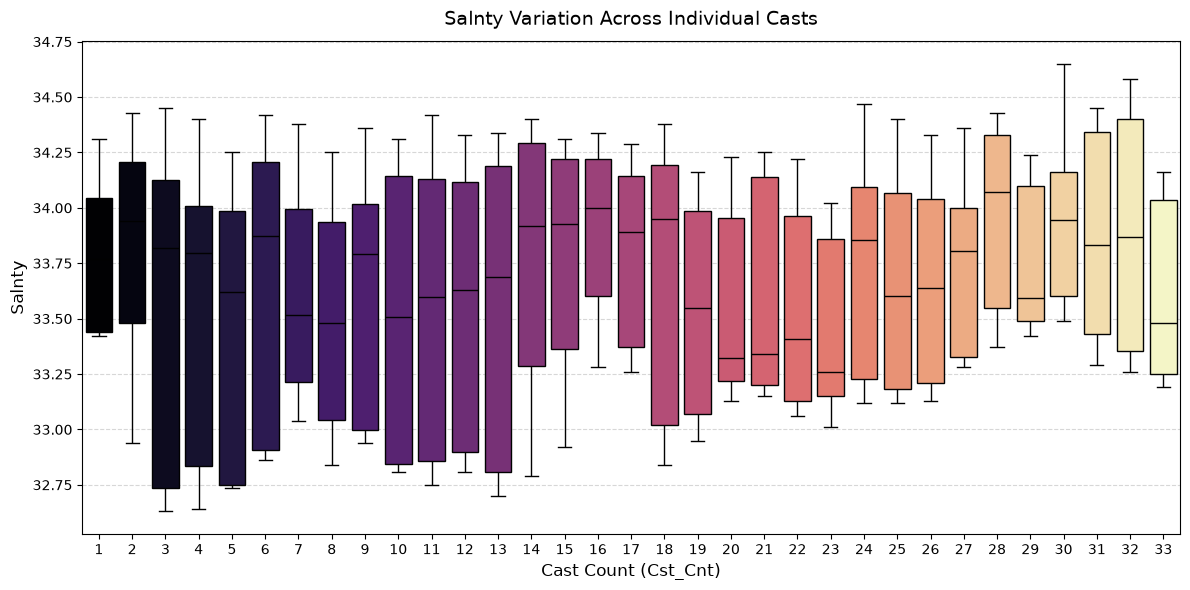

In [14]:
box_plot_per_cast_for_col('Salnty')

No outliers detected

<Axes: xlabel='Salnty', ylabel='Density'>

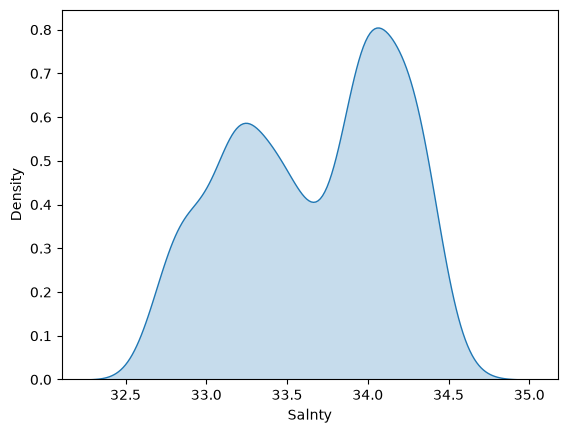

In [15]:
sns.kdeplot(df1.Salnty,fill=True)

But this a dual modal distribution therfore filling it with mean or median, wont work

In [16]:
df1.head(40)

,Cst_Cnt,Btl_Cnt,Sta_ID,Depth_ID,Depthm,T_degC,Salnty,STheta,RecInd,T_prec,...,DarkAq,MeanAq,R_Depth,R_TEMP,R_POTEMP,R_SALINITY,R_SIGMA,R_SVA,R_DYNHT,R_PRES
0,1,1,054.0 056.0,19-4903CR-HY-060-0930-05400560-0000A-3,0,10.50,33.440,25.649,3,1.0,...,9,9,0.0,10.50,10.50,33.440,25.64,233.0,0.00,0
1,1,2,054.0 056.0,19-4903CR-HY-060-0930-05400560-0008A-3,8,10.46,33.440,25.656,3,2.0,...,9,9,8.0,10.46,10.46,33.440,25.65,232.5,0.01,8
2,1,3,054.0 056.0,19-4903CR-HY-060-0930-05400560-0010A-7,10,10.46,33.437,25.654,7,2.0,...,9,9,10.0,10.46,10.46,33.437,25.65,232.8,0.02,10
3,1,4,054.0 056.0,19-4903CR-HY-060-0930-05400560-0019A-3,19,10.45,33.420,25.643,3,2.0,...,9,9,19.0,10.45,10.45,33.420,25.64,234.1,0.04,19
4,1,5,054.0 056.0,19-4903CR-HY-060-0930-05400560-0020A-7,20,10.45,33.421,25.643,7,2.0,...,9,9,20.0,10.45,10.45,33.421,25.64,234.0,0.04,20
5,1,6,054.0 056.0,19-4903CR-HY-060-0930-05400560-0030A-7,30,10.45,33.431,25.651,7,2.0,...,9,9,30.0,10.45,10.45,33.431,25.65,233.5,0.07,30
6,1,7,054.0 056.0,19-4903CR-HY-060-0930-05400560-0039A-3,39,10.45,33.440,25.658,3,2.0,...,9,9,39.0,10.45,10.45,33.440,25.65,233.0,0.09,39
7,1,8,054.0 056.0,19-4903CR-HY-060-0930-05400560-0050A-7,50,10.24,33.424,25.682,7,2.0,...,9,9,50.0,10.24,10.23,33.424,25.68,231.0,0.11,50
8,1,9,054.0 056.0,19-4903CR-HY-060-0930-05400560-0058A-3,58,10.06,33.420,25.710,3,2.0,...,9,9,58.0,10.06,10.05,33.420,25.71,228.5,0.13,58
9,1,10,054.0 056.0,19-4903CR-HY-060-0930-05400560-0075A-7,75,9.86,33.494,25.801,7,2.0,...,9,9,75.0,9.86,9.85,33.494,25.80,220.1,0.17,75


Trying to understand the relation between salinity of each cast

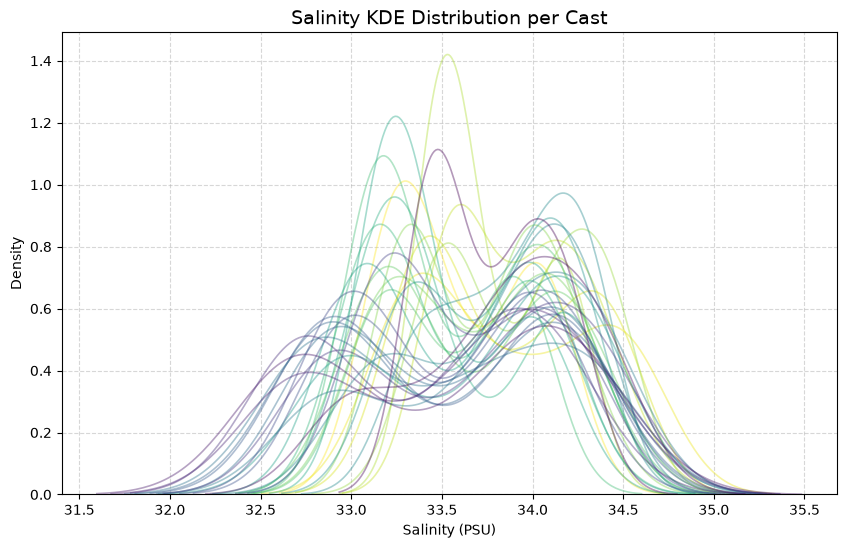

In [17]:

plt.figure(figsize=(10, 6))

# Plot KDE for each unique cast
sns.kdeplot(
    data=df1,
    x="Salnty",
    hue="Cst_Cnt",
    common_norm=False,  # Normalizes each cast individually
    palette="viridis",  # Smooth color mapping across casts
    alpha=0.4,          # Slight transparency to handle overlap
    linewidth=1.2,
)

plt.title("Salinity KDE Distribution per Cast", fontsize=14)
plt.xlabel("Salinity (PSU)")
plt.ylabel("Density")
plt.grid(True, linestyle="--", alpha=0.5)

# If you have dozens/hundreds of casts, hide the massive legend
plt.legend([], frameon=False) 

plt.show()

In [18]:
df1['Salnty_Imputed'] = df1.groupby('Cst_Cnt')['Salnty'].transform(lambda group: group.interpolate(method='linear'))


In [19]:
df1['Salnty_Imputed_Mean'] = df1['Salnty'].fillna(df1['Salnty'].mean())


Text(0.5, 1.0, 'Imputed By Linear Interpolation Vs Orginal Salinity Values')

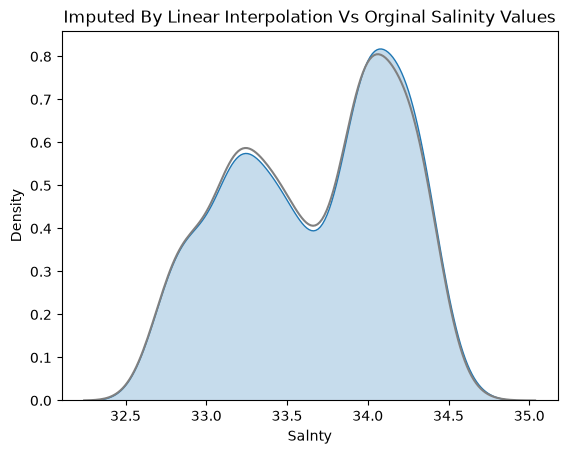

In [20]:
sns.kdeplot(df1.Salnty,color='Gray')
sns.kdeplot(df1.Salnty_Imputed,fill=True)
plt.title("Imputed By Linear Interpolation vs Orginal Salinity values".title())

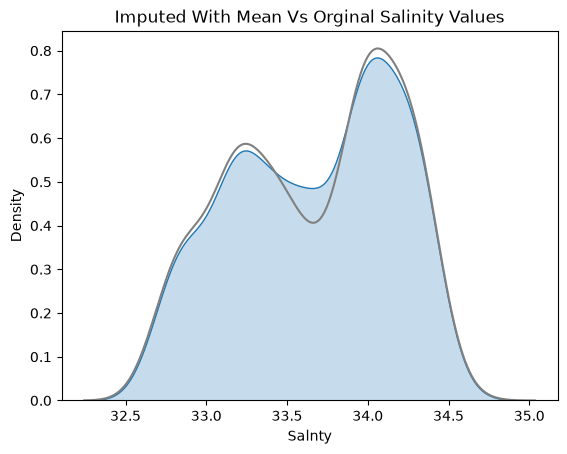

In [21]:
sns.kdeplot(df1.Salnty,color='Gray')
sns.kdeplot(df1.Salnty_Imputed_Mean,fill=True)
plt.title("Imputed with Mean vs Orginal Salinity values".title())
df1.drop(labels='Salnty_Imputed_Mean',axis=1,inplace=True)

## Filling STheta

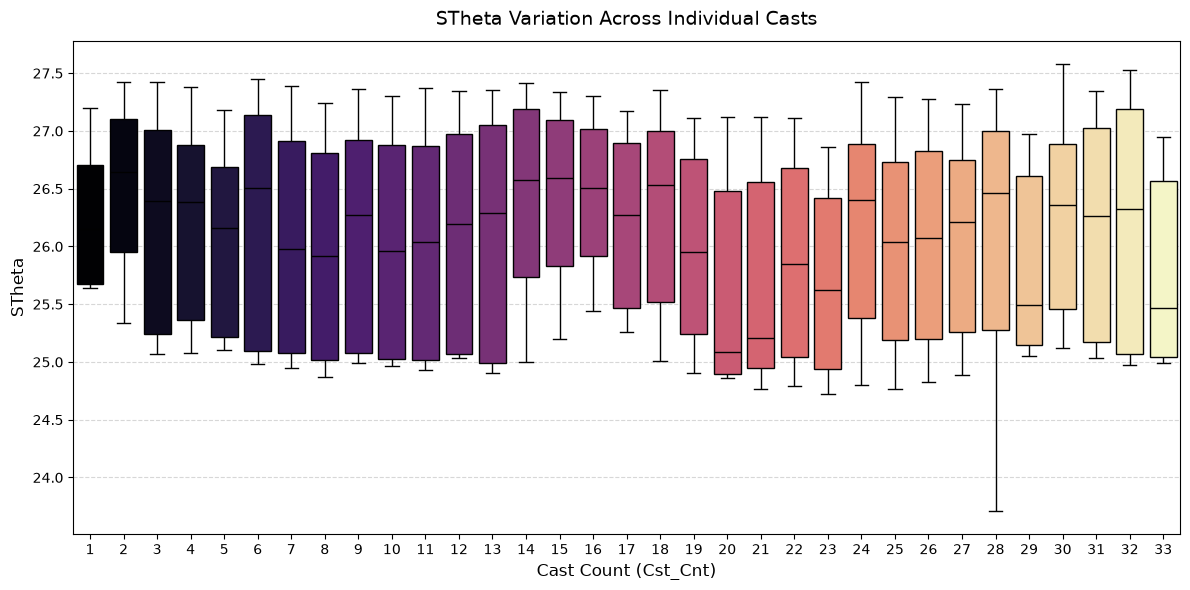

In [22]:
box_plot_per_cast_for_col('STheta')

In [23]:
df1.STheta.isnull().sum()

np.int64(32)

Text(0.5, 1.0, 'Density Distribution Stheta')

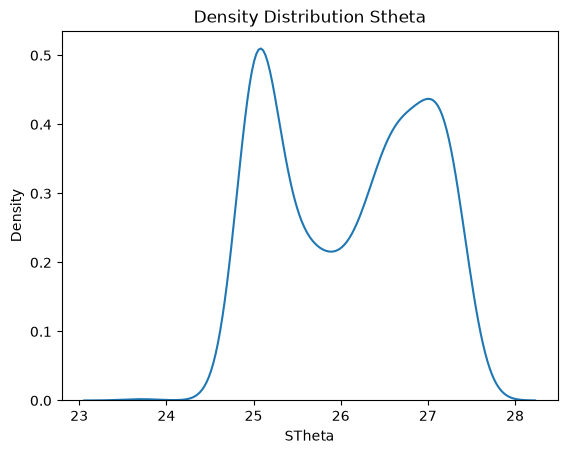

In [24]:
sns.kdeplot(df1,x="STheta")
plt.title("Density distribution STheta".title())

`STheta` is also following a bimodal distribution, let now see how it distributed with each cast

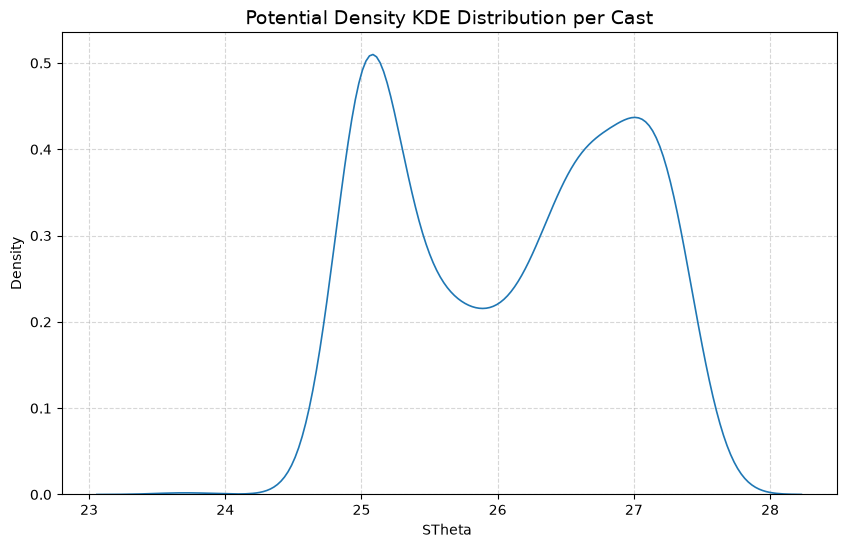

In [25]:

plt.figure(figsize=(10, 6))

# Plot KDE for each unique cast
sns.kdeplot(
    data=df1,
    x="STheta",
    common_norm=False,  # Normalizes each cast individually
    linewidth=1.2,
)

plt.title("Potential Density KDE Distribution per Cast", fontsize=14)
plt.xlabel("STheta ")
plt.ylabel("Density")
plt.grid(True, linestyle="--", alpha=0.5)

# If you have dozens/hundreds of casts, hide the massive legend
plt.legend([], frameon=False) 

plt.show()

In [26]:
df1['STheta_Imputed'] = df1.groupby('Cst_Cnt')['STheta'].transform(lambda grp: grp.interpolate(mode="linear"))

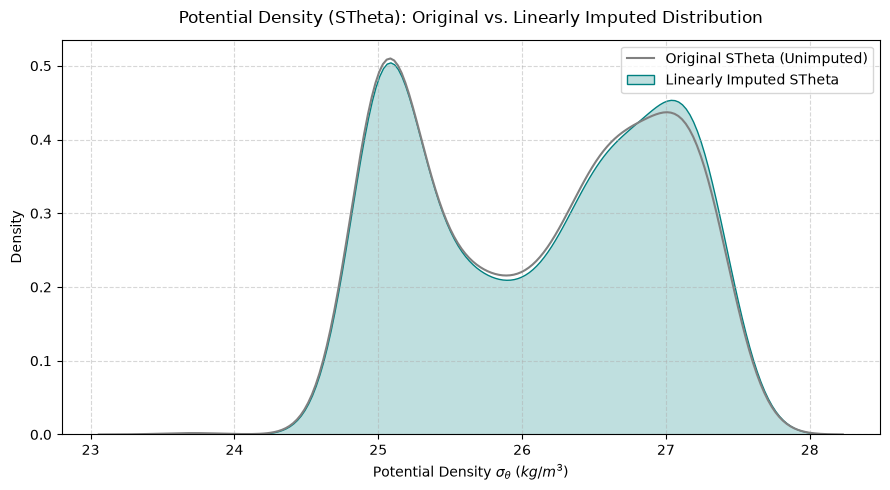

In [27]:
plt.figure(figsize=(9, 5))
sns.kdeplot(df1.STheta,color='Gray',label='Original STheta (Unimputed)')
sns.kdeplot(df1.STheta_Imputed,color='teal',fill=True,label='Linearly Imputed STheta')
plt.title('Potential Density (STheta): Original vs. Linearly Imputed Distribution', fontsize=12, pad=12)
plt.xlabel(r'Potential Density $\sigma_\theta$ ($kg/m^3$)', fontsize=10)
plt.ylabel('Density', fontsize=10)

# Display Legend explicitly
plt.legend(loc='upper right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [28]:
df1.STheta.isna().sum()

np.int64(32)

In [29]:
# remove this later
get_na_cols()

T_degC  ,  2
Salnty  ,  30
STheta  ,  32
T_prec  ,  2
S_prec  ,  30
R_TEMP  ,  2
R_POTEMP  ,  38
R_SALINITY  ,  30
R_SIGMA  ,  55
R_SVA  ,  55
R_DYNHT  ,  27


# Filling S_prec

S_Prec is the precision of the salinity recording

In [30]:
df1.S_prec.isna().sum()

np.int64(30)

In [31]:
df1.dropna(subset='S_prec',inplace=True)

Removing na values , rather than filling it with mode would be more acceptable
ie 30 out of 1000 values

## Filling T_degC

<Axes: xlabel='T_degC', ylabel='Density'>

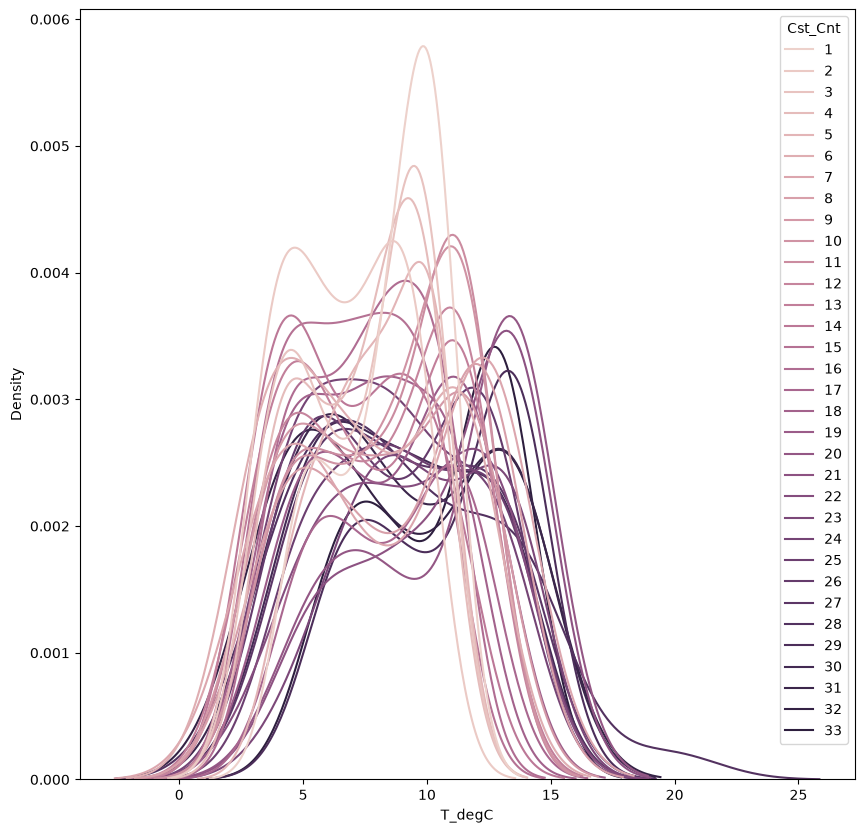

In [32]:
plt.figure(figsize=(10,10))
sns.kdeplot(df1,x="T_degC",hue=df1.Cst_Cnt)

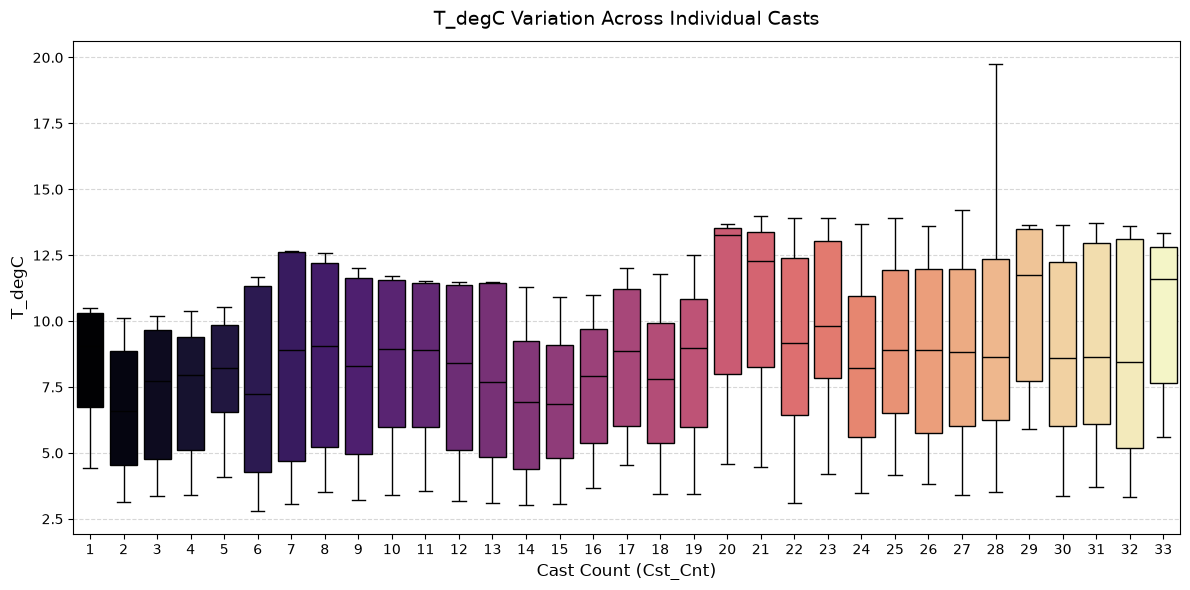

In [33]:
box_plot_per_cast_for_col('T_degC')

In [34]:
df1['T_degC_Imputed'] = df1.groupby('Cst_Cnt')['T_degC'].transform(lambda group: group.interpolate(method='linear'))


## Filling T_prec

In [35]:
df1.T_prec.isna().sum()

np.int64(2)

only two so dropping it would suffice

In [36]:
df1.dropna(subset=['T_prec'],inplace=True)

<Axes: xlabel='R_POTEMP', ylabel='Density'>

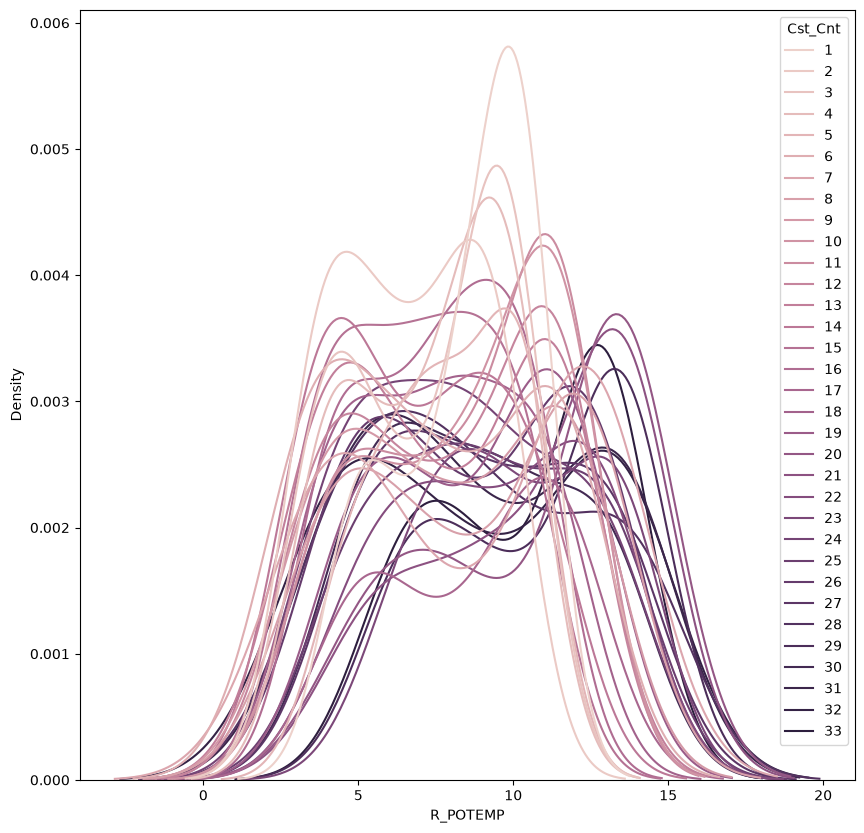

In [37]:
plt.figure(figsize=(10,10))
sns.kdeplot(df1,x='R_POTEMP',hue='Cst_Cnt')

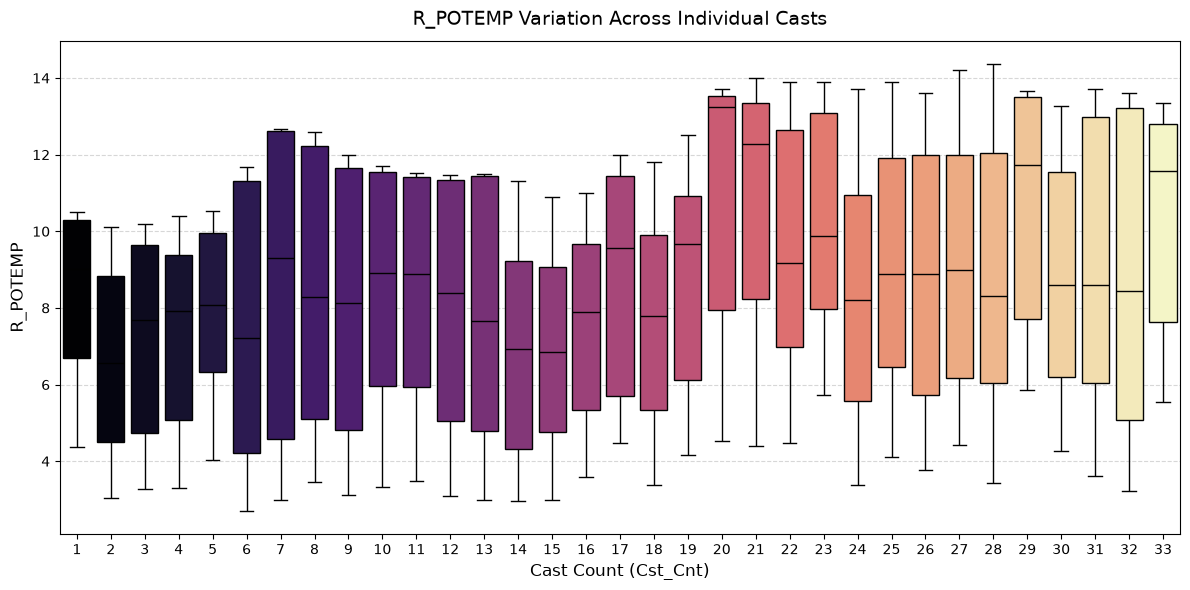

In [38]:
box_plot_per_cast_for_col('R_POTEMP',df1)

In [39]:
df1['R_POTEMP'] = df1.groupby('Cst_Cnt')['R_POTEMP'].transform(lambda grp: grp.interpolate(mode="linear"))

## Filling in R_POTEMP

In [40]:
df1.dropna(subset=['R_POTEMP'],inplace=True)

## Filling in R_SIGMA

<Axes: xlabel='R_SIGMA', ylabel='Density'>

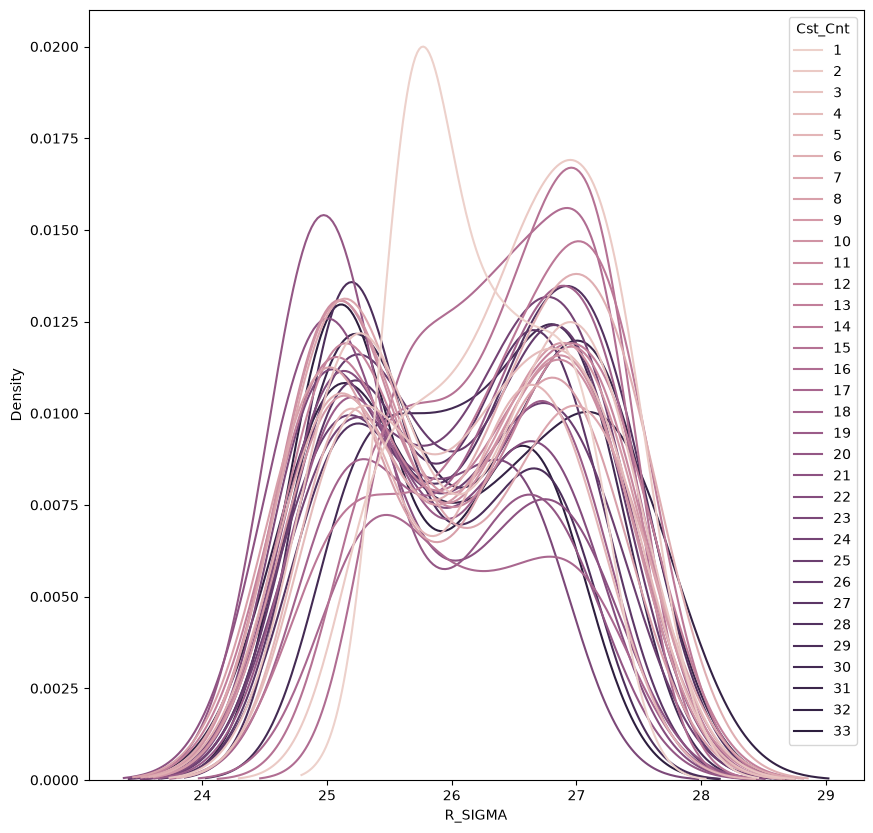

In [41]:
plt.figure(figsize=(10,10))
sns.kdeplot(df1,x="R_SIGMA",hue="Cst_Cnt")

In [42]:
df1['R_SIGMA'] = df1.groupby('Cst_Cnt')['R_SIGMA'].transform(lambda grp: grp.interpolate(mode="linear"))

## filling in R_SVA

<Axes: xlabel='R_SIGMA', ylabel='Density'>

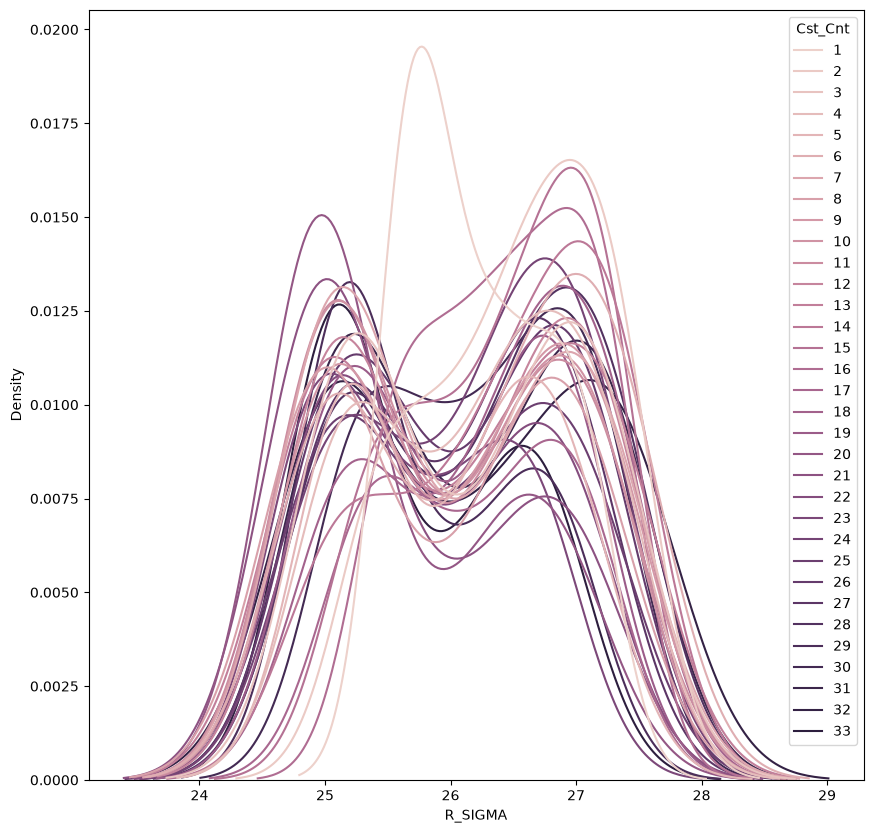

In [43]:
plt.figure(figsize=(10,10))
sns.kdeplot(df1,x="R_SIGMA",hue="Cst_Cnt")

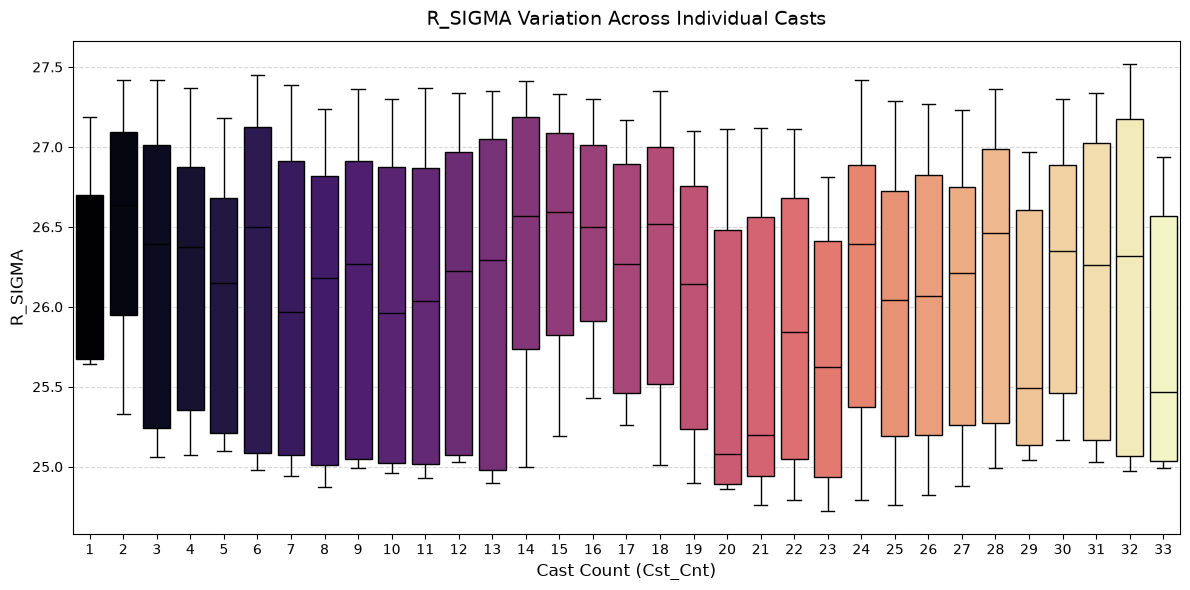

In [44]:
box_plot_per_cast_for_col('R_SIGMA')

In [45]:
df1['R_SVA'] = df1.groupby('Cst_Cnt')['R_SVA'].transform(lambda grp: grp.interpolate(mode="linear"))

In [46]:
get_na_cols()

R_DYNHT  ,  5


# Filling R_DYNHT

In [47]:
df1.dropna(subset=['R_DYNHT'],inplace=True)

In [48]:
get_na_cols()